# Analisis Penjualan Toko Shopee Perlengkapan Rumah Tangga (Juli–September 2026)

**Darren Gunawan** · Data Analyst Bootcamp · Python (pandas, matplotlib, seaborn) + Power BI

---

## Konteks
Toko ini menjual perlengkapan rumah tangga (container box, keranjang, peralatan dapur, alat kebersihan, dll.) melalui Shopee dan berlokasi di Bandung. Data yang dipakai adalah **ekspor pesanan berstatus *Selesai*** dari Shopee Seller Centre untuk tiga bulan: Juli, Agustus, dan September 2026.

## Problem Statement
Pemilik toko belum memiliki gambaran berbasis data tentang **produk apa yang mendorong penjualan, kapan pembeli paling aktif, siapa pembelinya, dan seberapa sering mereka kembali**. Tanpa itu, keputusan stok, jadwal operasional, dan promosi masih berdasarkan perkiraan.

## Analytics Questions
1. Bagaimana performa penjualan per bulan (revenue, jumlah pesanan, nilai rata-rata pesanan)?
2. Kapan (hari dan jam) pesanan paling ramai?
3. Kategori dan produk apa yang menyumbang revenue terbesar?
4. Dari mana pembeli berasal, dan bagaimana mereka membayar serta memilih pengiriman?
5. Seberapa banyak pembeli yang kembali membeli (repeat customer)?
6. Seberapa besar retur, dan kategori apa yang paling sering diretur?

> **Catatan privasi:** data asli berisi nama, nomor telepon, alamat, dan username pembeli. Semua kolom pribadi **dihapus atau diganti ID anonim** di langkah pertama, sebelum data ditampilkan atau diekspor.

## 1. Setup

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:,.2f}'.format)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

BLUE, ORANGE, GREY = '#1F5FAD', '#E0782F', '#9AA5B1'

def rupiah_juta(x, pos=None):
    """Format sumbu grafik: 12500000 -> 'Rp12,5 jt'"""
    return f'Rp{x/1e6:,.1f} jt'.replace('.', ',')

def rp(x):
    """Format angka rupiah untuk teks: 1250000 -> 'Rp1.250.000'"""
    return 'Rp' + f'{x:,.0f}'.replace(',', '.')

### Load data
Upload **ketiga file** `Order.completed....xlsx` sekaligus. Semua kolom dibaca sebagai **teks** dulu, karena ekspor Shopee menyimpan angka uang dengan titik sebagai pemisah ribuan (contoh: `"109.000"`). Kalau langsung dibaca sebagai angka, `"8.500"` akan terbaca 8,5.

In [2]:
try:
    from google.colab import files
    uploaded = files.upload()
    file_list = sorted(f for f in uploaded.keys() if f.endswith('.xlsx'))
except ImportError:                      # kalau dijalankan di luar Colab
    file_list = sorted(glob.glob('*Order.completed*.xlsx'))

raw = pd.concat([pd.read_excel(f, dtype=str) for f in file_list], ignore_index=True)
print(f'{len(file_list)} file dimuat | {raw.shape[0]:,} baris x {raw.shape[1]} kolom')

3 file dimuat | 3,652 baris x 51 kolom


## 2. Anonimisasi data
Langkah ini dilakukan **sebelum** data ditampilkan, supaya tidak ada data pribadi di notebook maupun file hasil ekspor.

- Kolom pribadi dihapus: nama penerima, nomor telepon, alamat, nomor resi, catatan pembeli.
- `Username (Pembeli)` diganti `customer_id` (CUST_0001, CUST_0002, …) berdasarkan urutan pesanan pertama.
- `No. Pesanan` diganti `order_id` (ORD_00001, …).

In [3]:
pii_cols = ['Nama Penerima', 'No. Telepon', 'Alamat Pengiriman', 'No. Resi',
            'Catatan dari Pembeli', 'Catatan']

first_buy = raw.groupby('Username (Pembeli)')['Waktu Pesanan Dibuat'].min().sort_values()
cust_map = {u: f'CUST_{i:04d}' for i, u in enumerate(first_buy.index, 1)}

first_order = raw.groupby('No. Pesanan')['Waktu Pesanan Dibuat'].min().sort_values()
order_map = {o: f'ORD_{i:05d}' for i, o in enumerate(first_order.index, 1)}

raw['customer_id'] = raw['Username (Pembeli)'].map(cust_map)
raw['order_id'] = raw['No. Pesanan'].map(order_map)

df = raw.drop(columns=pii_cols + ['Username (Pembeli)', 'No. Pesanan'])
del raw                                   # data mentah tidak dipakai lagi

print('Kolom pribadi yang dihapus:', pii_cols + ['Username (Pembeli)', 'No. Pesanan'])
print('Ukuran data setelah anonimisasi:', df.shape)

Kolom pribadi yang dihapus: ['Nama Penerima', 'No. Telepon', 'Alamat Pengiriman', 'No. Resi', 'Catatan dari Pembeli', 'Catatan', 'Username (Pembeli)', 'No. Pesanan']
Ukuran data setelah anonimisasi: (3652, 45)


## 3. Data Understanding

In [4]:
summary = pd.DataFrame({
    'non_null': df.notna().sum(),
    'missing': df.isna().sum(),
    'unique': df.nunique(),
    'contoh_nilai': df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
})
summary

,non_null,missing,unique,contoh_nilai
Status Pesanan,3652,0,1,Selesai
Shipped by Advance Fulfilment,3652,0,1,N
Booking SN,0,3652,0,NaN
Status Pembatalan/ Pengembalian,42,3610,2,Permintaan Disetujui
Opsi Pengiriman,3652,0,14,Instant-GrabExpress Instant
Antar ke counter/ pick-up,3652,0,2,Pickup
Pesanan Harus Dikirimkan Sebelum (Menghindari keterlambatan),3652,0,1309,2026-09-01 10:59
Waktu Pengiriman Diatur,3650,2,2425,2026-09-01 08:55
Waktu Pesanan Dibuat,3652,0,2643,2026-09-01 08:08
Waktu Pembayaran Dilakukan,3652,0,2632,2026-09-01 08:09


In [5]:
print('Jumlah baris (item)  :', f"{len(df):,}")
print('Jumlah pesanan unik  :', f"{df['order_id'].nunique():,}")
print('Jumlah pembeli unik  :', f"{df['customer_id'].nunique():,}")
print('Jumlah produk unik   :', f"{df['Nama Produk'].nunique():,}")
print('Periode pesanan      :', df['Waktu Pesanan Dibuat'].min(), 's/d', df['Waktu Pesanan Dibuat'].max())
print()
for col in ['Status Pesanan', 'Status Pembatalan/ Pengembalian', 'Opsi Pengiriman', 'Metode Pembayaran']:
    print(f'--- {col}')
    print(df[col].value_counts(dropna=False).head(8).to_string(), '\n')

Jumlah baris (item)  : 3,652
Jumlah pesanan unik  : 2,772
Jumlah pembeli unik  : 2,446
Jumlah produk unik   : 574
Periode pesanan      : 2026-07-01 03:32 s/d 2026-09-30 21:53

--- Status Pesanan
Status Pesanan
Selesai    3652 

--- Status Pembatalan/ Pengembalian
Status Pembatalan/ Pengembalian
NaN                     3610
Permintaan Disetujui      38
Masalah Diselesaikan       4 

--- Opsi Pengiriman
Opsi Pengiriman
Instant-GrabExpress Instant                        1700
Instant Prioritas-GoSend Instant Prioritas         1139
Hemat Kargo-J&T Cargo                               283
Instant Prioritas-GrabExpress Instant Prioritas     138
Reguler (Cashless)-SPX Standard                     131
Reguler (Cashless)-SiCepat REG                       65
Instant-Gosend Instant                               53
Gosend Instant                                       52 

--- Metode Pembayaran
Metode Pembayaran
Online Payment               1042
Saldo ShopeePay               976
SPayLater            

**Hasil data understanding:**
- Satu baris = satu **produk dalam pesanan**. Satu pesanan bisa berisi beberapa baris (beberapa produk).
- Semua pesanan berstatus **Selesai**, karena file yang diekspor memang khusus pesanan selesai. Pesanan yang dibatalkan tidak termasuk dalam data ini.
- Empat kolom kosong seluruhnya (`Booking SN`, `Tipe Pesanan`, `SKU Induk`, `Nomor Referensi SKU`) sehingga dibuang di tahap cleaning.
- Kolom uang tersimpan sebagai teks dengan titik pemisah ribuan sehingga perlu dikonversi ke angka.
- Kolom seperti `Total Pembayaran`, ongkos kirim, dan voucher Shopee bernilai **per pesanan** (berulang di setiap baris produk), jadi harus dihitung di level pesanan agar tidak terhitung dobel.

## 4. Data Cleaning & Transformation

### 4.1 Buang kolom kosong, konversi angka dan tanggal

In [6]:
empty_cols = [c for c in df.columns if df[c].isna().all()]
df = df.drop(columns=empty_cols)
print('Kolom kosong yang dibuang:', empty_cols)

money_cols = ['Harga Awal', 'Harga Setelah Diskon', 'Subtotal Pesanan', 'Total Diskon',
              'Diskon Dari Penjual', 'Diskon Dari Shopee', 'Voucher Ditanggung Penjual',
              'Voucher Ditanggung Shopee', 'Potongan Koin Shopee', 'Diskon Kartu Kredit',
              'Ongkos Kirim Dibayar oleh Pembeli', 'Estimasi Potongan Biaya Pengiriman',
              'Total Pembayaran', 'Perkiraan Ongkos Kirim']
for c in money_cols:
    df[c] = pd.to_numeric(df[c].fillna('0').str.replace('.', '', regex=False), errors='coerce')

for c in ['Jumlah', 'Returned quantity', 'Jumlah Produk di Pesan']:
    df[c] = pd.to_numeric(df[c])

for c in ['Waktu Pesanan Dibuat', 'Waktu Pembayaran Dilakukan', 'Waktu Pesanan Selesai']:
    df[c] = pd.to_datetime(df[c], errors='coerce')

df[['Harga Awal', 'Harga Setelah Diskon', 'Subtotal Pesanan', 'Total Pembayaran']].describe()

Kolom kosong yang dibuang: ['Booking SN', 'Tipe Pesanan', 'SKU Induk', 'Nomor Referensi SKU']


,Harga Awal,Harga Setelah Diskon,Subtotal Pesanan,Total Pembayaran
count,"3,652.00","3,652.00","3,652.00","3,652.00"
mean,"73,220.04","73,190.56","115,076.99","143,329.09"
std,"85,798.58","85,815.60","149,566.50","141,232.84"
min,280.00,280.00,900.00,0.00
25%,"16,900.00","16,900.00","22,500.00","47,987.50"
50%,"41,900.00","41,900.00","61,400.00","96,607.00"
75%,"107,000.00","107,000.00","142,150.00","190,202.50"
max,"829,000.00","829,000.00","1,800,000.00","1,533,200.00"


### 4.2 Validasi data

In [7]:
cek = pd.Series({
    'Baris duplikat': df.duplicated().sum(),
    'Subtotal != harga x jumlah': ((df['Subtotal Pesanan'] - df['Harga Setelah Diskon'] * df['Jumlah']).abs() > 1).sum(),
    'Harga negatif / nol': (df['Harga Setelah Diskon'] <= 0).sum(),
    'Konversi uang gagal (NaN)': df[money_cols].isna().sum().sum(),
    'Tanggal gagal dibaca': df['Waktu Pesanan Dibuat'].isna().sum(),
})
cek.to_frame('jumlah_masalah')

,jumlah_masalah
Baris duplikat,0
Subtotal != harga x jumlah,0
Harga negatif / nol,0
Konversi uang gagal (NaN),0
Tanggal gagal dibaca,0


Semua pengecekan bernilai 0: tidak ada duplikat, subtotal konsisten dengan harga × jumlah, dan seluruh angka serta tanggal berhasil dikonversi.

### 4.3 Feature engineering
Kolom baru yang ditambahkan:
- **Waktu:** bulan, tanggal, nama hari, jam pesanan
- **Kategori produk:** dikelompokkan dari kata kunci di nama produk (574 produk → 13 kategori)
- **Jenis pengiriman:** Instant (same-day), Reguler, Kargo
- **Kelompok pembayaran** dan **wilayah** (Bandung Raya / Jawa Barat lainnya / luar Jawa Barat)
- **Revenue bersih:** subtotal dikurangi nilai barang yang diretur

In [8]:
import re

# --- Waktu ---
df['order_datetime'] = df['Waktu Pesanan Dibuat']
df['order_date'] = df['order_datetime'].dt.date
df['month'] = df['order_datetime'].dt.to_period('M').astype(str)
hari = {0: 'Senin', 1: 'Selasa', 2: 'Rabu', 3: 'Kamis', 4: 'Jumat', 5: 'Sabtu', 6: 'Minggu'}
df['day_num'] = df['order_datetime'].dt.dayofweek
df['day_name'] = df['day_num'].map(hari)
df['hour'] = df['order_datetime'].dt.hour

# --- Kategori produk (aturan kata kunci, dicek berurutan) ---
category_rules = [
    ('Perlengkapan Gas',        r'\bGAS\b|ELPIJI|LPG|REGULATOR'),
    ('Container Box',           r'CONTAINER BOX|KOTAK PENYIMPANAN RODA|\bCB ?\d'),
    ('Keranjang',               r'KERANJANG|RIGEN|BASKET'),
    ('Tempat Sampah',           r'SAMPAH'),
    ('Rak & Laci',              r'\bRAK\b|\bLACI\b|LEMARI|GANTUNGAN|HANGER'),
    ('Furnitur Plastik',        r'KURSI|BANGKU|\bMEJA\b|DINGKLIK'),
    ('Ember, Baskom & Bak',     r'EMBER|BASKOM|\bBAK\b|GAYUNG|\bTONG\b|GILES'),
    ('Alat Kebersihan',         r'\bPEL\b|SAPU|SIKAT|SABUT|SERABUT|PEMBERSIH|\bLAP\b|PENGKI|KESET|FLOOR WIPER|SLEBER'),
    ('Toples & Wadah Makanan',  r'TOPLES|WADAH|FOOD|LUNCH|RANTANG|TEMPAT MAKAN|TEMPAT BUMBU|TUMBLER'),
    ('Peralatan Dapur & Makan', r'SENDOK|GARPU|PISAU|PANCI|KASTROL|TEKO|GELAS|PIRING|NAMPAN|MANGKO|MANGKUK|CETAKAN|KUE|'
                                r'TALENAN|SARINGAN|BOTOL|TAMPAH|NYIRU|ULEKAN|COBEK|WAJAN|DANDANG|SPATULA|TERMOS|CENTONG|'
                                r'PARUT|CANGKIR|BAKI|DAPUR|PRESS|MIXER|CHOPPER|BLENDER|KOMPOR|PEELER|PERASAN|PENGOCOK|TUDUNG SAJI'),
    ('Kotak & Box Serbaguna',   r'KOTAK|\bBOX\b|STORAGE|ORGANIZER'),
    ('Pot & Tanaman',           r'\bPOT\b|TANAMAN|PENYIRAM'),
]
def categorize(name):
    name = str(name).upper()
    for cat, pattern in category_rules:
        if re.search(pattern, name):
            return cat
    return 'Lainnya'
df['category'] = df['Nama Produk'].map(categorize)

# Nama produk pendek untuk grafik
df['product_short'] = (df['Nama Produk'].str.split('/').str[0].str.strip().str.title().str.slice(0, 45))

# --- Pengiriman, pembayaran, wilayah ---
def shipping_type(s):
    s = str(s).upper()
    if 'CARGO' in s:
        return 'Kargo'
    if 'INSTANT' in s:
        return 'Instant (same-day)'
    return 'Reguler'
df['shipping_type'] = df['Opsi Pengiriman'].map(shipping_type)

payment_map = {
    'Saldo ShopeePay': 'ShopeePay', 'SPayLater': 'SPayLater', 'QRIS': 'QRIS',
    'Online Payment': 'Online Payment', 'SeaBank Bayar Instan': 'SeaBank',
    'Kartu Kredit/Debit': 'Kartu Kredit/Debit', 'Cicilan Kartu Kredit': 'Kartu Kredit/Debit',
    'Alfamart/Alfamidi/Dan+Dan': 'Gerai Retail', 'Indomaret/i.Saku': 'Gerai Retail',
}
df['payment_group'] = df['Metode Pembayaran'].map(payment_map).fillna('Lainnya')

bandung_raya = ['KOTA BANDUNG', 'KAB. BANDUNG', 'KOTA CIMAHI', 'KAB. BANDUNG BARAT']
df['region'] = np.select(
    [df['Kota/Kabupaten'].isin(bandung_raya), df['Provinsi'].eq('JAWA BARAT')],
    ['Bandung Raya', 'Jawa Barat lainnya'], default='Luar Jawa Barat')

# --- Revenue & retur ---
df['revenue'] = df['Subtotal Pesanan']
df['returned_value'] = df['Returned quantity'] * df['Harga Setelah Diskon']
df['net_revenue'] = df['revenue'] - df['returned_value']
df['is_returned'] = df['Returned quantity'] > 0

df['category'].value_counts()

category
Peralatan Dapur & Makan    634
Container Box              627
Keranjang                  434
Ember, Baskom & Bak        323
Kotak & Box Serbaguna      318
Toples & Wadah Makanan     298
Alat Kebersihan            291
Rak & Laci                 159
Tempat Sampah              155
Lainnya                    154
Perlengkapan Gas           125
Pot & Tanaman               77
Furnitur Plastik            57
Name: count, dtype: int64

### 4.4 Tabel level pesanan
Satu baris = satu pesanan. Tabel ini dipakai untuk metrik per pesanan (AOV, metode pembayaran, jam pesanan, pembeli berulang) supaya kolom per pesanan tidak terhitung dobel.

In [9]:
orders = (df.groupby('order_id')
            .agg(customer_id=('customer_id', 'first'),
                 order_datetime=('order_datetime', 'first'),
                 order_date=('order_date', 'first'),
                 month=('month', 'first'),
                 day_num=('day_num', 'first'),
                 day_name=('day_name', 'first'),
                 hour=('hour', 'first'),
                 city=('Kota/Kabupaten', 'first'),
                 province=('Provinsi', 'first'),
                 region=('region', 'first'),
                 payment_method=('Metode Pembayaran', 'first'),
                 payment_group=('payment_group', 'first'),
                 shipping_option=('Opsi Pengiriman', 'first'),
                 shipping_type=('shipping_type', 'first'),
                 items_qty=('Jumlah', 'sum'),
                 product_lines=('Nama Produk', 'size'),
                 product_revenue=('revenue', 'sum'),
                 net_revenue=('net_revenue', 'sum'),
                 total_payment=('Total Pembayaran', 'first'),
                 shopee_voucher=('Voucher Ditanggung Shopee', 'first'),
                 buyer_shipping_fee=('Ongkos Kirim Dibayar oleh Pembeli', 'first'),
                 has_return=('is_returned', 'max'))
            .reset_index()
            .sort_values('order_datetime'))

orders['has_shopee_voucher'] = orders['shopee_voucher'] > 0
orders['customer_order_no'] = orders.groupby('customer_id').cumcount() + 1
orders['customer_type'] = np.where(orders['customer_order_no'] == 1, 'Pembeli baru', 'Pembeli kembali')

print(orders.shape)
orders.head()

(2772, 26)


,order_id,customer_id,order_datetime,order_date,month,day_num,day_name,hour,city,province,region,payment_method,payment_group,shipping_option,shipping_type,items_qty,product_lines,product_revenue,net_revenue,total_payment,shopee_voucher,buyer_shipping_fee,has_return,has_shopee_voucher,customer_order_no,customer_type
0,ORD_00001,CUST_0001,2026-07-01 03:32:00,2026-07-01,2026-07,2,Rabu,3,KOTA BANDUNG,JAWA BARAT,Bandung Raya,Online Payment,Online Payment,Instant Prioritas-GoSend Instant Prioritas,Instant (same-day),1,1,141000,141000,116605,28200,0,False,True,1,Pembeli baru
1,ORD_00002,CUST_0002,2026-07-01 04:51:00,2026-07-01,2026-07,2,Rabu,4,KAB. BEKASI,JAWA BARAT,Jawa Barat lainnya,Online Payment,Online Payment,Reguler (Cashless)-SPX Standard,Reguler,2,1,29000,29000,19386,10000,0,False,True,1,Pembeli baru
2,ORD_00003,CUST_0003,2026-07-01 05:30:00,2026-07-01,2026-07,2,Rabu,5,KOTA CIMAHI,JAWA BARAT,Bandung Raya,Online Payment,Online Payment,Instant Prioritas-GoSend Instant Prioritas,Instant (same-day),1,1,118900,118900,109010,11890,0,False,True,1,Pembeli baru
3,ORD_00004,CUST_0004,2026-07-01 06:02:00,2026-07-01,2026-07,2,Rabu,6,KOTA CIMAHI,JAWA BARAT,Bandung Raya,Saldo ShopeePay,ShopeePay,Instant Prioritas-GoSend Instant Prioritas,Instant (same-day),10,3,93700,93700,95100,0,0,False,False,1,Pembeli baru
4,ORD_00005,CUST_0005,2026-07-01 08:41:00,2026-07-01,2026-07,2,Rabu,8,KOTA BANDUNG,JAWA BARAT,Bandung Raya,SPayLater,SPayLater,Instant Prioritas-GoSend Instant Prioritas,Instant (same-day),1,1,141000,141000,133800,14100,3000,False,True,1,Pembeli baru


## 5. Analisis

### Q1. Bagaimana performa penjualan per bulan?

In [10]:
monthly = (orders.groupby('month')
             .agg(revenue=('product_revenue', 'sum'),
                  orders=('order_id', 'nunique'),
                  customers=('customer_id', 'nunique'),
                  units=('items_qty', 'sum'))
             .assign(aov=lambda x: x['revenue'] / x['orders']))
monthly['revenue_mom_%'] = monthly['revenue'].pct_change() * 100
monthly['orders_mom_%'] = monthly['orders'].pct_change() * 100

total_rev, total_orders = orders['product_revenue'].sum(), orders['order_id'].nunique()
print('Total revenue produk :', rp(total_rev))
print('Total pesanan        :', f'{total_orders:,}')
print('Total unit terjual   :', f"{orders['items_qty'].sum():,}")
print('AOV (rata-rata/pesanan):', rp(total_rev / total_orders))
monthly

Total revenue produk : Rp420.261.182
Total pesanan        : 2,772
Total unit terjual   : 8,823
AOV (rata-rata/pesanan): Rp151.609


,revenue,orders,customers,units,aov,revenue_mom_%,orders_mom_%
month,,,,,,,
2026-07,142014750,1008,929,3286,"140,887.65",NaN,NaN
2026-08,140777374,914,822,2923,"154,023.39",-0.87,-9.33
2026-09,137469058,850,765,2614,"161,728.30",-2.35,-7.00


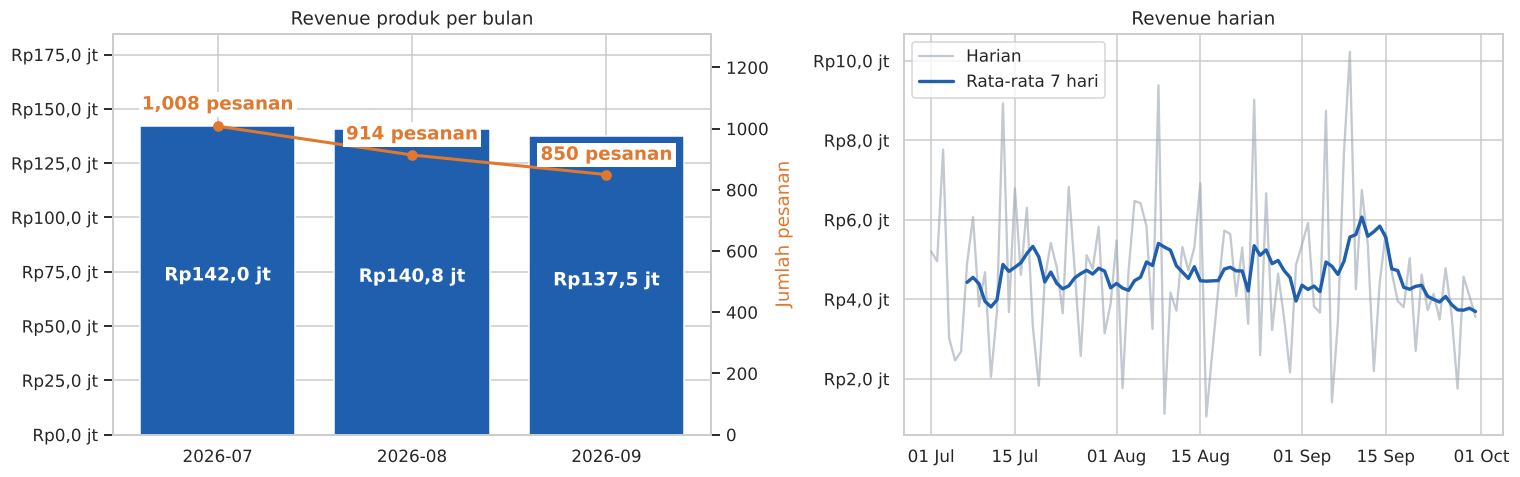

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax = axes[0]
ax.bar(monthly.index, monthly['revenue'], color=BLUE)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(rupiah_juta))
ax.set_title('Revenue produk per bulan')
ax.set_ylim(0, monthly['revenue'].max() * 1.3)
for i, v in enumerate(monthly['revenue']):
    ax.text(i, v * 0.5, rupiah_juta(v), ha='center', color='white', fontweight='bold')
ax2 = ax.twinx()
ax2.plot(monthly.index, monthly['orders'], color=ORANGE, marker='o', linewidth=2)
ax2.set_ylabel('Jumlah pesanan', color=ORANGE)
ax2.set_ylim(0, monthly['orders'].max() * 1.3)
for i, v in enumerate(monthly['orders']):
    ax2.text(i, v * 1.04, f'{v:,} pesanan', ha='center', va='bottom', color=ORANGE,
             fontweight='bold', bbox=dict(facecolor='white', edgecolor='none', pad=2))
ax2.grid(False)

daily = orders.groupby('order_date')['product_revenue'].sum()
daily.index = pd.to_datetime(daily.index)
ax = axes[1]
ax.plot(daily.index, daily, color=GREY, alpha=0.6, label='Harian')
ax.plot(daily.index, daily.rolling(7).mean(), color=BLUE, linewidth=2.2, label='Rata-rata 7 hari')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(rupiah_juta))
ax.set_title('Revenue harian')
import matplotlib.dates as mdates
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.legend()
plt.tight_layout()
plt.show()

📌 **Temuan Q1**
- Selama Juli–September 2026 toko mencatat **revenue produk Rp420,3 juta** dari **2.772 pesanan** dan **8.823 unit** terjual, dengan **AOV Rp151.609** per pesanan.
- Revenue relatif **stabil** (−0,9% di Agustus, −2,4% di September), tetapi **jumlah pesanan turun** cukup tajam: 1.008 → 914 → 850 (−9,3% lalu −7,0%). Jumlah pembeli juga turun dari 929 menjadi 765.
- Penurunan pesanan tertutup oleh **AOV yang naik** dari Rp140.888 menjadi Rp161.728 (+14,8%). Artinya, pembeli yang tersisa berbelanja lebih besar per pesanan, tetapi toko kehilangan jumlah transaksi.

### Q2. Kapan pesanan paling ramai?

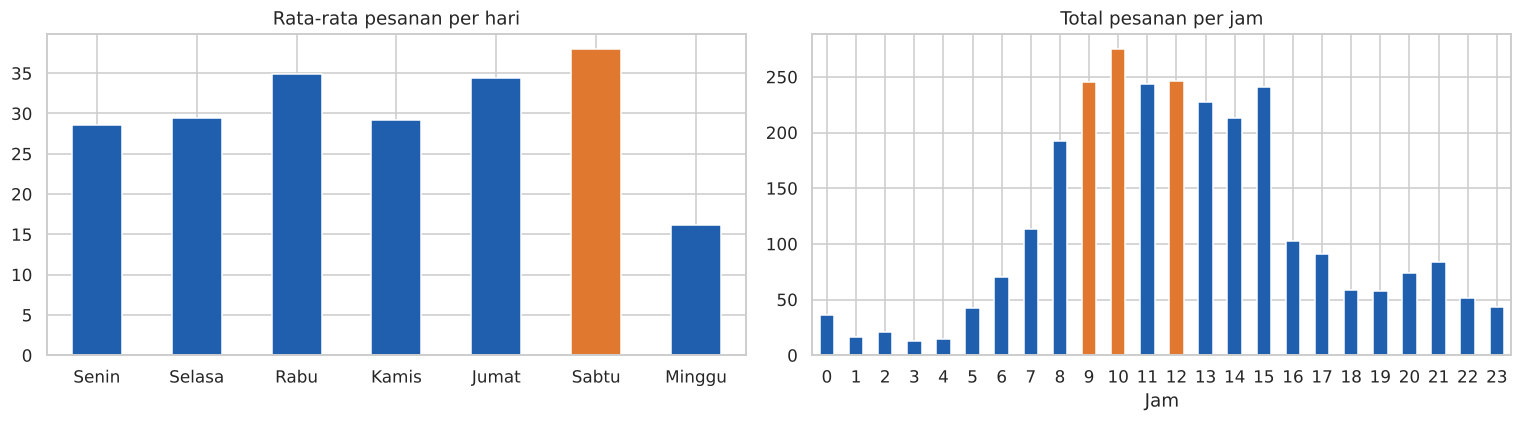

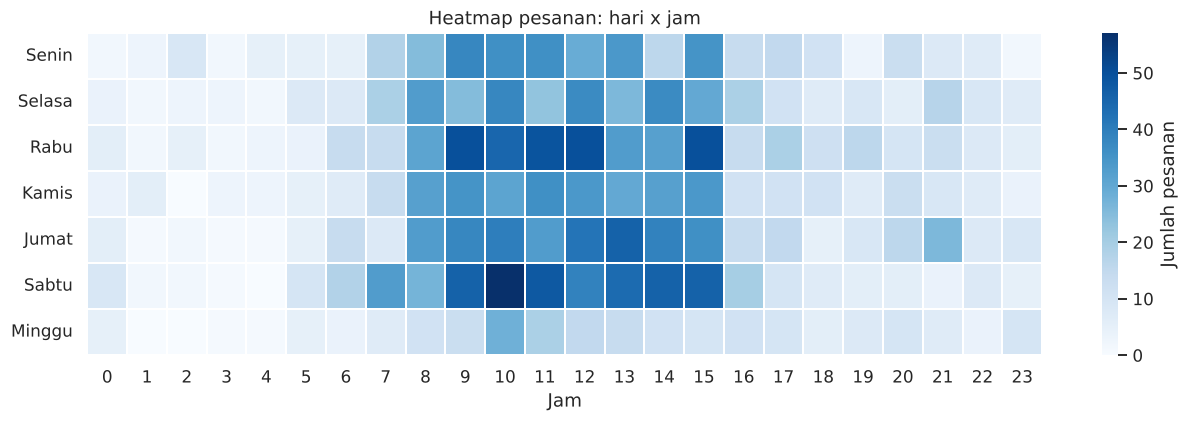

Pesanan pada jam 08.00-16.59: 71.6%
3 jam tersibuk: [10, 12, 9]


In [12]:
day_order = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']
# jumlah hari kalender per nama hari dalam periode (Juli-September = 92 hari)
calendar = pd.Series(pd.date_range(orders['order_datetime'].min().normalize(),
                                   orders['order_datetime'].max().normalize()))
days_per_name = calendar.dt.dayofweek.map(hari).value_counts()

by_day = (orders.groupby('day_name')['order_id'].count() / days_per_name).reindex(day_order).rename('rata2_pesanan_per_hari')
by_hour = orders.groupby('hour')['order_id'].count().rename('pesanan')
heat = orders.pivot_table(index='day_name', columns='hour', values='order_id', aggfunc='count').reindex(day_order).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
by_day.plot.bar(ax=axes[0], color=[ORANGE if v == by_day.max() else BLUE for v in by_day])
axes[0].set_title('Rata-rata pesanan per hari')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=0)
by_hour.plot.bar(ax=axes[1], color=[ORANGE if v >= by_hour.nlargest(3).min() else BLUE for v in by_hour])
axes[1].set_title('Total pesanan per jam')
axes[1].set_xlabel('Jam')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 3.8))
sns.heatmap(heat, cmap='Blues', linewidths=0.3, cbar_kws={'label': 'Jumlah pesanan'})
plt.title('Heatmap pesanan: hari x jam')
plt.xlabel('Jam'); plt.ylabel('')
plt.show()

jam_kerja = orders['hour'].between(8, 16).mean() * 100
print(f'Pesanan pada jam 08.00-16.59: {jam_kerja:.1f}%')
print('3 jam tersibuk:', by_hour.nlargest(3).index.tolist())

📌 **Temuan Q2**
- Pesanan terkonsentrasi di **jam kerja**: 71,6% pesanan masuk pukul 08.00–16.59, dengan puncak pukul **09.00–12.59** (jam tersibuk: 10.00). Setelah pukul 16.00 jumlah pesanan turun lebih dari separuh.
- **Sabtu** adalah hari teramai (rata-rata 38 pesanan/hari), disusul **Rabu** (34,9) dan **Jumat** (34,4).
- **Minggu** paling sepi: hanya 16,2 pesanan/hari, kurang dari separuh hari Sabtu. Pola ini sejalan dengan pengiriman instant yang bergantung pada jam operasional toko.

### Q3. Kategori dan produk apa yang menyumbang revenue terbesar?

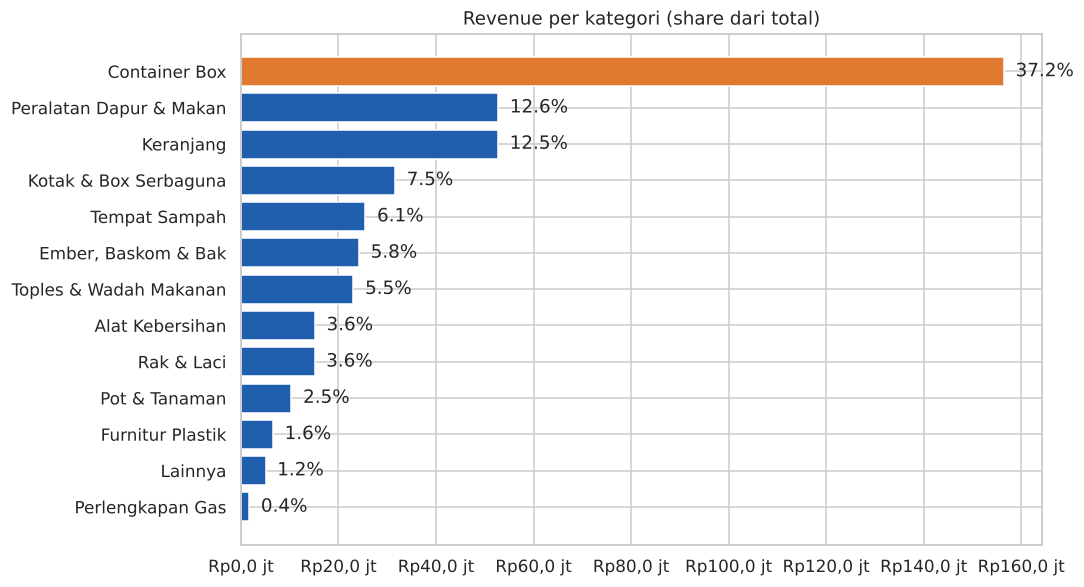

,revenue,units,orders,products,share_%,avg_price
category,,,,,,
Container Box,156459000,1060,585,38,37.23,"147,602.83"
Peralatan Dapur & Makan,52751150,1183,540,137,12.55,"44,591.00"
Keranjang,52718932,1001,408,64,12.54,"52,666.27"
Kotak & Box Serbaguna,31600500,612,292,35,7.52,"51,634.80"
Tempat Sampah,25517400,227,144,37,6.07,"112,411.45"
"Ember, Baskom & Bak",24215592,434,288,66,5.76,"55,796.29"
Toples & Wadah Makanan,23072160,1528,276,51,5.49,"15,099.58"
Alat Kebersihan,15161800,398,229,49,3.61,"38,094.97"
Rak & Laci,15088100,231,150,31,3.59,"65,316.45"


In [13]:
cat_perf = (df.groupby('category')
              .agg(revenue=('revenue', 'sum'), units=('Jumlah', 'sum'),
                   orders=('order_id', 'nunique'), products=('Nama Produk', 'nunique'))
              .sort_values('revenue', ascending=False))
cat_perf['share_%'] = cat_perf['revenue'] / cat_perf['revenue'].sum() * 100
cat_perf['avg_price'] = cat_perf['revenue'] / cat_perf['units']

fig, ax = plt.subplots(figsize=(10, 5.5))
plot_df = cat_perf.sort_values('revenue')
ax.barh(plot_df.index, plot_df['revenue'],
        color=[ORANGE if c == cat_perf.index[0] else BLUE for c in plot_df.index])
ax.xaxis.set_major_formatter(mtick.FuncFormatter(rupiah_juta))
for i, (v, s) in enumerate(zip(plot_df['revenue'], plot_df['share_%'])):
    ax.text(v, i, f'  {s:.1f}%', va='center')
ax.set_title('Revenue per kategori (share dari total)')
plt.tight_layout()
plt.show()
cat_perf

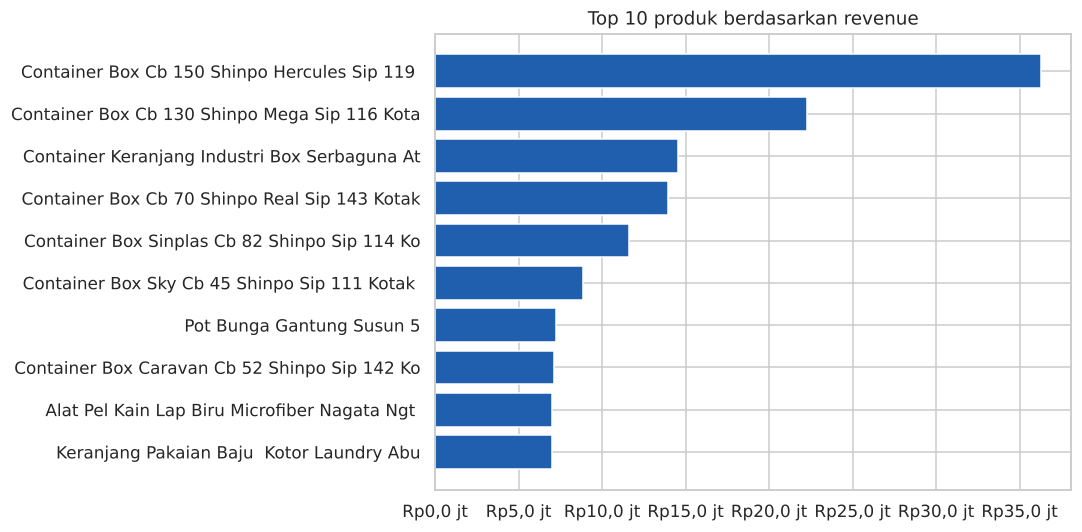

Jumlah produk terjual: 557
98 produk (17.6%) menyumbang 80% revenue
Top 10 produk menyumbang 32.3% revenue


,revenue,units,category,cum_share_%
product_short,,,,
Container Box Cb 150 Shinpo Hercules Sip 119,36288000,126,Container Box,8.63
Container Box Cb 130 Shinpo Mega Sip 116 Kota,22265100,99,Container Box,13.93
Container Keranjang Industri Box Serbaguna At,14566500,135,Keranjang,17.40
Container Box Cb 70 Shinpo Real Sip 143 Kotak,13959000,99,Container Box,20.72
Container Box Sinplas Cb 82 Shinpo Sip 114 Ko,11602500,65,Container Box,23.48
Container Box Sky Cb 45 Shinpo Sip 111 Kotak,8832000,96,Container Box,25.58
Pot Bunga Gantung Susun 5,7241000,47,Pot & Tanaman,27.31
Container Box Caravan Cb 52 Shinpo Sip 142 Ko,7134000,60,Container Box,29.00
Alat Pel Kain Lap Biru Microfiber Nagata Ngt,7011000,69,Alat Kebersihan,30.67


In [14]:
prod = (df.groupby('product_short')
          .agg(revenue=('revenue', 'sum'), units=('Jumlah', 'sum'), category=('category', 'first'))
          .sort_values('revenue', ascending=False))
prod['cum_share_%'] = prod['revenue'].cumsum() / prod['revenue'].sum() * 100

top10 = prod.head(10)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top10.index[::-1], top10['revenue'][::-1], color=BLUE)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(rupiah_juta))
ax.set_title('Top 10 produk berdasarkan revenue')
plt.tight_layout()
plt.show()

n_prod = len(prod)
n_80 = (prod['cum_share_%'] <= 80).sum() + 1
print(f'Jumlah produk terjual: {n_prod}')
print(f'{n_80} produk ({n_80 / n_prod * 100:.1f}%) menyumbang 80% revenue')
print(f'Top 10 produk menyumbang {top10["revenue"].sum() / prod["revenue"].sum() * 100:.1f}% revenue')
top10

📌 **Temuan Q3**
- **Container Box** adalah penggerak utama: **37,2% revenue** (Rp156,5 juta) hanya dari 38 produk, dengan harga rata-rata tertinggi (±Rp147 ribu/unit). Bersama **Peralatan Dapur & Makan (12,6%)** dan **Keranjang (12,5%)**, tiga kategori ini menyumbang **62,3%** revenue.
- **6 dari 10 produk terlaris** adalah container box Shinpo. Produk nomor 1, *Container Box CB 150*, menyumbang Rp36,3 juta (8,6% revenue).
- Penjualan mengikuti pola **Pareto**: **98 produk (17,6%) menghasilkan 80% revenue**, dari total 557 produk yang terjual.
- **Perlengkapan Gas** (karet seal tabung) terjual paling banyak secara unit (1.675 unit) tetapi hanya 0,4% revenue karena harganya ±Rp1.000. Produk ini berperan sebagai *add-on* murah, bukan sumber revenue.

### Q4. Dari mana pembeli berasal, dan bagaimana mereka membayar serta memilih pengiriman?

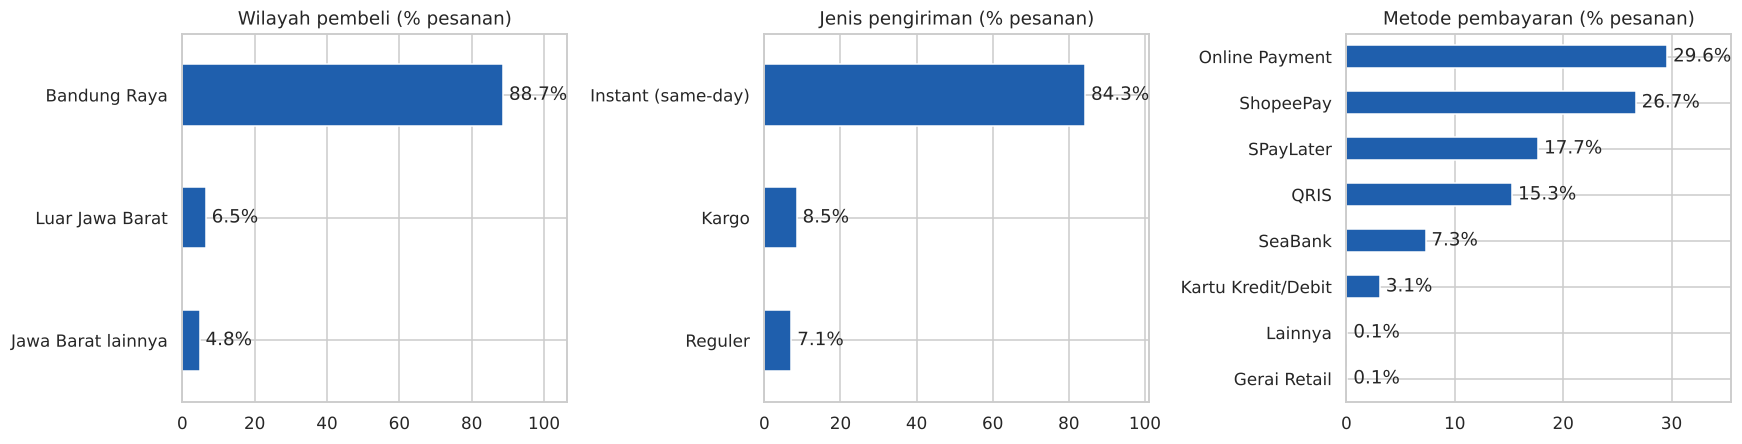

Top kota (% pesanan):
city
KOTA BANDUNG         56.90
KAB. BANDUNG         16.60
KOTA CIMAHI           9.10
KAB. BANDUNG BARAT    6.10
KAB. SUMEDANG         1.40
KAB. BEKASI           0.50 

AOV per jenis pengiriman:
shipping_type
Instant (same-day)    Rp157.083
Kargo                 Rp174.589
Reguler                Rp59.499 

Pesanan dengan voucher Shopee: 82.3%
AOV dengan vs tanpa voucher Shopee:
has_shopee_voucher
False     Rp73.292
True     Rp168.468


In [15]:
def share(s):
    return (s.value_counts(normalize=True) * 100).round(1)

region_share = share(orders['region'])
ship_share = share(orders['shipping_type'])
pay_share = share(orders['payment_group'])
city_top = share(orders['city']).head(6)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, data, title in zip(axes, [region_share, ship_share, pay_share],
                           ['Wilayah pembeli (% pesanan)', 'Jenis pengiriman (% pesanan)', 'Metode pembayaran (% pesanan)']):
    data.sort_values().plot.barh(ax=ax, color=BLUE)
    ax.set_title(title)
    for i, v in enumerate(data.sort_values()):
        ax.text(v, i, f' {v:.1f}%', va='center')
    ax.set_xlim(0, data.max() * 1.2)
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

aov_ship = orders.groupby('shipping_type')['product_revenue'].mean().map(rp)
voucher_rate = orders['has_shopee_voucher'].mean() * 100
aov_voucher = orders.groupby('has_shopee_voucher')['product_revenue'].mean().map(rp)
print('Top kota (% pesanan):'); print(city_top.to_string(), '\n')
print('AOV per jenis pengiriman:'); print(aov_ship.to_string(), '\n')
print(f'Pesanan dengan voucher Shopee: {voucher_rate:.1f}%')
print('AOV dengan vs tanpa voucher Shopee:'); print(aov_voucher.to_string())

📌 **Temuan Q4**
- Pembeli sangat **lokal**: **88,7% pesanan dari Bandung Raya** (Kota Bandung saja 56,9%). Hanya 6,5% pesanan berasal dari luar Jawa Barat.
- **84,3% pesanan memakai pengiriman Instant (same-day)**. Pengiriman reguler hanya 7,1% dengan AOV jauh lebih kecil (Rp59.499 vs Rp157.083 untuk instant), sedangkan kargo dipakai untuk pesanan besar (AOV Rp174.589).
- Metode pembayaran tersebar: **Online Payment 29,6%, ShopeePay 26,7%, SPayLater 17,7%, QRIS 15,3%**. Hampir 1 dari 5 pesanan memakai paylater.
- **82,3% pesanan memakai voucher dari Shopee**, dan AOV pesanan bervoucher (Rp168.468) jauh di atas pesanan tanpa voucher (Rp73.292). Sebaliknya, **toko sama sekali tidak memakai voucher sendiri** (nilai voucher penjual = 0 di semua pesanan).

### Q5. Seberapa banyak pembeli yang kembali membeli?

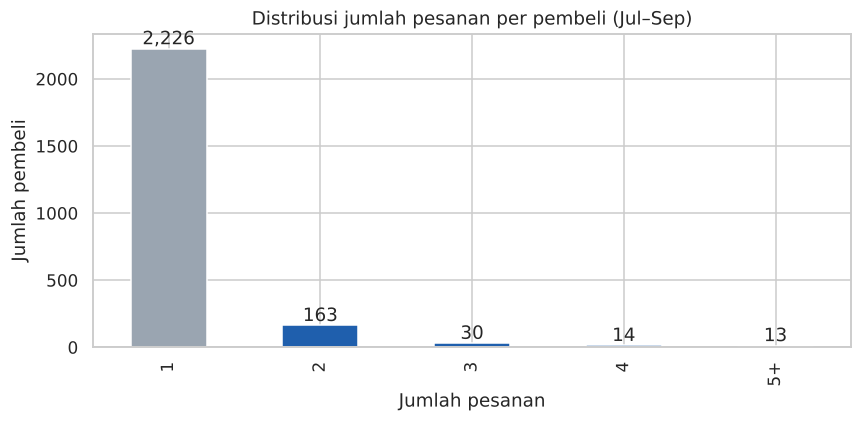

Repeat customer rate: 9.0%


,customers,orders,revenue,share_customers_%,share_revenue_%,revenue_per_customer
segment,,,,,,
Repeat (2+ pesanan),220,546,140912150,8.99,33.53,"640,509.77"
Sekali beli,2226,2226,279349032,91.01,66.47,"125,493.73"


In [16]:
cust = (orders.groupby('customer_id')
          .agg(n_orders=('order_id', 'nunique'), revenue=('product_revenue', 'sum')))
cust['segment'] = np.where(cust['n_orders'] > 1, 'Repeat (2+ pesanan)', 'Sekali beli')

repeat_rate = (cust['n_orders'] > 1).mean() * 100
seg = cust.groupby('segment').agg(customers=('n_orders', 'size'), orders=('n_orders', 'sum'), revenue=('revenue', 'sum'))
seg['share_customers_%'] = seg['customers'] / seg['customers'].sum() * 100
seg['share_revenue_%'] = seg['revenue'] / seg['revenue'].sum() * 100
seg['revenue_per_customer'] = seg['revenue'] / seg['customers']

dist = cust['n_orders'].clip(upper=5).value_counts().sort_index()
dist.index = [str(i) if i < 5 else '5+' for i in dist.index]

fig, ax = plt.subplots(figsize=(8, 4))
dist.plot.bar(ax=ax, color=[GREY] + [BLUE] * (len(dist) - 1))
ax.set_title('Distribusi jumlah pesanan per pembeli (Jul–Sep)')
ax.set_xlabel('Jumlah pesanan'); ax.set_ylabel('Jumlah pembeli')
for i, v in enumerate(dist):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

print(f'Repeat customer rate: {repeat_rate:.1f}%')
seg

📌 **Temuan Q5**
- Dari 2.446 pembeli, hanya **220 pembeli (9,0%) yang membeli lebih dari sekali** dalam tiga bulan.
- Namun kelompok kecil ini menyumbang **33,5% revenue**. Nilai belanja per pembeli repeat **Rp640.510**, sekitar **5 kali** pembeli sekali beli (Rp125.494).
- Mayoritas pembeli (2.226 orang) hanya bertransaksi satu kali, jadi ada ruang besar untuk meningkatkan pembelian ulang.

### Q6. Seberapa besar retur, dan kategori apa yang paling sering diretur?

In [17]:
ret_lines = df['is_returned'].sum()
ret_units = df['Returned quantity'].sum()
ret_value = df['returned_value'].sum()
print(f'Baris produk diretur : {ret_lines} dari {len(df):,} ({ret_lines / len(df) * 100:.2f}%)')
print(f'Unit diretur         : {ret_units} dari {df["Jumlah"].sum():,} ({ret_units / df["Jumlah"].sum() * 100:.2f}%)')
print(f'Nilai retur          : {rp(ret_value)} ({ret_value / df["revenue"].sum() * 100:.2f}% dari revenue)')

ret_cat = (df.groupby('category')
             .agg(units=('Jumlah', 'sum'), returned_units=('Returned quantity', 'sum'),
                  returned_value=('returned_value', 'sum'))
             .assign(return_rate_units_pct=lambda x: x['returned_units'] / x['units'] * 100)
             .sort_values('returned_value', ascending=False))
ret_cat[ret_cat['returned_units'] > 0]

Baris produk diretur : 42 dari 3,652 (1.15%)
Unit diretur         : 65 dari 8,823 (0.74%)
Nilai retur          : Rp3.628.000 (0.86% dari revenue)


,units,returned_units,returned_value,return_rate_units_pct
category,,,,
Peralatan Dapur & Makan,1183,19,1269800,1.61
Container Box,1060,8,1095600,0.75
Keranjang,1001,5,450600,0.50
Toples & Wadah Makanan,1528,11,206200,0.72
"Ember, Baskom & Bak",434,9,179800,2.07
Alat Kebersihan,398,7,167800,1.76
Tempat Sampah,227,1,156900,0.44
Rak & Laci,231,3,63300,1.30
Furnitur Plastik,156,2,38000,1.28


📌 **Temuan Q6**
- Tingkat retur **sangat rendah**: 65 dari 8.823 unit (**0,74%**), senilai **Rp3,63 juta (0,86% revenue)**.
- Nilai retur terbesar berasal dari **Peralatan Dapur & Makan** (Rp1,27 juta) dan **Container Box** (Rp1,10 juta).
- Tingkat retur per unit tertinggi ada di **Ember, Baskom & Bak (2,1%)** dan **Alat Kebersihan (1,8%)**, sehingga dua kategori ini perlu dicek dari sisi kualitas barang atau pengemasan.

## 6. Insight & Rekomendasi

### Jawaban analytics questions
1. **Performa bulanan:** revenue stabil di ±Rp140 juta/bulan, tetapi jumlah pesanan turun 16% dari Juli ke September. Revenue bertahan karena AOV naik 14,8%.
2. **Waktu ramai:** pukul 09.00–13.00, terutama hari Sabtu, Rabu, dan Jumat. Minggu paling sepi.
3. **Produk:** Container Box menyumbang 37% revenue, dan 18% produk menghasilkan 80% revenue.
4. **Pembeli:** 89% dari Bandung Raya, 84% memakai pengiriman instant, dan 82% memakai voucher Shopee. Toko belum memakai voucher sendiri.
5. **Repeat customer:** hanya 9% pembeli, tetapi menyumbang sepertiga revenue.
6. **Retur:** sangat rendah (0,74% unit), relatif tertinggi di ember/baskom dan alat kebersihan.

### Rekomendasi
1. **Lindungi produk andalan.** Jaga stok dan visibilitas container box (terutama CB 150, CB 130, CB 70) karena 6 dari 10 produk terlaris ada di kategori ini. Kehabisan stok di sini langsung berdampak ke revenue.
2. **Hentikan penurunan jumlah pesanan.** Toko belum memakai voucher sendiri. Uji **voucher toko** (misalnya untuk follower atau minimal belanja tertentu) dan bandingkan jumlah pesanan sebelum dan sesudahnya.
3. **Bangun pembelian ulang.** Pembeli repeat bernilai 5 kali lipat. Kirim voucher pembelian berikutnya atau pesan tindak lanjut setelah pesanan selesai, terutama untuk produk yang dibeli berulang seperti karet seal gas dan keranjang.
4. **Sesuaikan operasional dengan jam ramai.** Siapkan tim packing dan admin chat pada pukul 09.00–13.00, dan jadwalkan iklan atau flash sale di hari Sabtu dan Rabu. Hari Minggu bisa dipakai untuk restock atau uji promo khusus.
5. **Naikkan nilai pesanan kecil.** Tawarkan bundling produk murah (karet seal gas, sabut, toples) sebagai *add-on* untuk produk utama, terutama pada pesanan reguler yang AOV-nya rendah.
6. **Cek kualitas kategori dengan retur tertinggi** (ember/baskom dan alat kebersihan): periksa barang sebelum dikirim dan perkuat pengemasan.

### Keterbatasan
- Data hanya berisi **pesanan selesai**, sehingga tingkat pembatalan tidak bisa dianalisis.
- Periode hanya 3 bulan, sehingga pola musiman belum bisa disimpulkan.
- Kategori produk dibuat dari aturan kata kunci nama produk, jadi sebagian kecil produk bisa masuk kategori yang kurang tepat (kategori *Lainnya* hanya 1,2% revenue).

## 7. Export data bersih untuk Power BI
Dua tabel diekspor (sudah dianonimkan):
- `shopee_items.csv` — satu baris per produk dalam pesanan (untuk analisis produk dan kategori)
- `shopee_orders.csv` — satu baris per pesanan (untuk metrik pesanan, pembeli, waktu, pembayaran, pengiriman)

Kedua tabel dihubungkan lewat kolom `order_id`.

In [18]:
items_export = df[['order_id', 'customer_id', 'order_datetime', 'order_date', 'month',
                   'Nama Produk', 'product_short', 'category', 'Nama Variasi',
                   'Harga Awal', 'Harga Setelah Diskon', 'Jumlah', 'Returned quantity',
                   'revenue', 'returned_value', 'net_revenue', 'is_returned']].rename(columns={
    'Nama Produk': 'product_name', 'Nama Variasi': 'variation', 'Harga Awal': 'price_original',
    'Harga Setelah Diskon': 'price', 'Jumlah': 'qty', 'Returned quantity': 'returned_qty'})

orders_export = orders.copy()

items_export.to_csv('shopee_items.csv', index=False)
orders_export.to_csv('shopee_orders.csv', index=False)
print('shopee_items.csv :', items_export.shape)
print('shopee_orders.csv:', orders_export.shape)

try:
    from google.colab import files
    files.download('shopee_items.csv')
    files.download('shopee_orders.csv')
except ImportError:
    pass

shopee_items.csv : (3652, 17)
shopee_orders.csv: (2772, 26)
